# SpamGuard — Data Understanding & Data Preparation

EDA for the SpamGuard capstone (Naive Bayes spam classifier). This notebook covers the **Data Understanding** and **Data Preparation** steps of the CRISP-DM plan from the proposal, before the Naive Bayes model is trained in a separate notebook.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 80)

DATA_PATH = 'emails.csv'  # place this notebook in the same folder as emails.csv, or update the path
PROCESSED_PATH = 'clean_emails.csv'


## 1. Load & Structural Check

In [2]:
df = pd.read_csv(r'C:\Users\Admin\OneDrive\Desktop\emails.csv')
print('Shape:', df.shape)
df.info()

Shape: (5728, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5728 non-null   str  
 1   spam    5728 non-null   int64
dtypes: int64(1), str(1)
memory usage: 8.6 MB


In [3]:
df.head(3)

,text,spam
0,Subject: naturally irresistible your corporate identity lt is really hard t...,1
1,Subject: the stock trading gunslinger fanny is merrill but muzo not colza a...,1
2,Subject: unbelievable new homes made easy im wanting to show you this home...,1


### 1.1 Missing values

In [4]:
missing = df.isna().sum()
print(missing)

text    0
spam    0
dtype: int64


### 1.2 Duplicate messages

In [5]:
n_dupes = df.duplicated(subset=['text']).sum()
print(f'Duplicate message rows: {n_dupes}')

df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Duplicate message rows: 33
Shape after dropping duplicates: (5695, 2)


### 1.3 Target column sanity check

In [6]:
print('Unique values in spam column:', df['spam'].unique())
df['label'] = df['spam'].map({0: 'safe', 1: 'spam'})

Unique values in spam column: [1 0]


### 1.4 Does this match the SMS Spam Collection described in the proposal?

Quick checks: every message should start with an SMS-style short body if it's the SMS Spam Collection. Here every row instead starts with an email `Subject:` line, and — as the word frequencies in Section 6 will show — the *safe* class is dominated by Enron-specific names (`enron`, `vince`, `kaminski`, `hou`), which is a strong signal this is an Enron-email-based spam dataset, not SMS messages.

In [7]:
pct_subject = df['text'].str.startswith('Subject:').mean()
print(f"Share of rows starting with 'Subject:': {pct_subject:.1%}")
print()
print('Longest message, first 200 chars:')
print(df.loc[df['text'].str.len().idxmax(), 'text'][:200])

Share of rows starting with 'Subject:': 100.0%

Longest message, first 200 chars:
Subject: from the enron india newsdesk - april 27 th newsclips  fyi news articles from indian press .  - - - - - - - - - - - - - - - - - - - - - - forwarded by sandeep kohli / enron _ development on 0


## 2. Class Balance

label
safe    4327
spam    1368
Name: count, dtype: int64
label
safe    0.76
spam    0.24
Name: proportion, dtype: float64


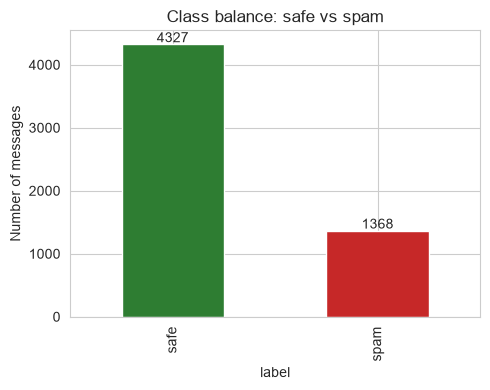

In [8]:
counts = df['label'].value_counts()
props = df['label'].value_counts(normalize=True)
print(counts)
print(props.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
counts.reindex(['safe', 'spam']).plot(kind='bar', color=['#2e7d32', '#c62828'], ax=ax)
ax.set_title('Class balance: safe vs spam')
ax.set_ylabel('Number of messages')
for i, v in enumerate(counts.reindex(['safe', 'spam'])):
    ax.text(i, v + 30, str(v), ha='center')
plt.tight_layout()
plt.show()

**Reading this:** the classes are imbalanced (roughly 76% safe / 24% spam), which is exactly the risk flagged in the proposal's risk register (Section 7, Risk #1). This is a reason to report precision, recall and F1 in the evaluation notebook rather than accuracy alone, and to consider `class_weight='balanced'`-style handling or resampling at modelling time.

## 3. Message Length & Structure

In [9]:
df['char_len'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().apply(len)
df['exclaim_count'] = df['text'].str.count('!')
df['digit_count'] = df['text'].str.count(r'\d')

df.groupby('label')[['char_len', 'word_count', 'exclaim_count', 'digit_count']].describe().T

label                        safe          spam
char_len      count   4327.000000   1368.000000
              mean    1634.200139   1317.257310
              std     1965.016383   2271.372893
              min       13.000000     18.000000
              25%      577.500000    401.500000
              50%     1122.000000    693.500000
              75%     2037.500000   1250.250000
              max    43952.000000  28432.000000
word_count    count   4327.000000   1368.000000
              mean     346.253293    266.432749
              std      407.188262    451.461674
              min        2.000000      4.000000
              25%      119.000000     79.000000
              50%      239.000000    139.500000
              75%      439.500000    251.000000
              max     8477.000000   6129.000000
exclaim_count count   4327.000000   1368.000000
              mean       0.428472      2.419591
              std        1.090625      5.209801
              min        0.000000      0.000000
              25%        0.000000      0.000000
              50%        0.000000      1.000000
              75%        0.000000      3.000000
              max       12.000000     88.000000
digit_count   count   4327.000000   1368.000000
              mean      41.418304     24.644006
              std       80.941874     52.689534
              min        0.000000      0.000000
              25%       10.000000      1.000000
              50%       26.000000      6.000000
              75%       54.000000     25.000000
              max     4149.000000    840.000000

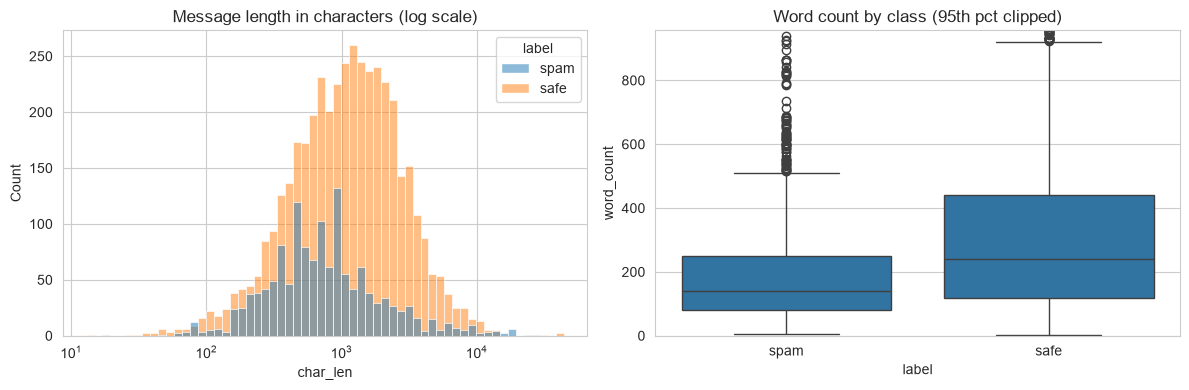

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x='char_len', hue='label', bins=60, log_scale=(True, False), ax=axes[0])
axes[0].set_title('Message length in characters (log scale)')

sns.boxplot(data=df, x='label', y='word_count', ax=axes[1])
axes[1].set_ylim(0, df['word_count'].quantile(0.95))
axes[1].set_title('Word count by class (95th pct clipped)')

plt.tight_layout()
plt.show()

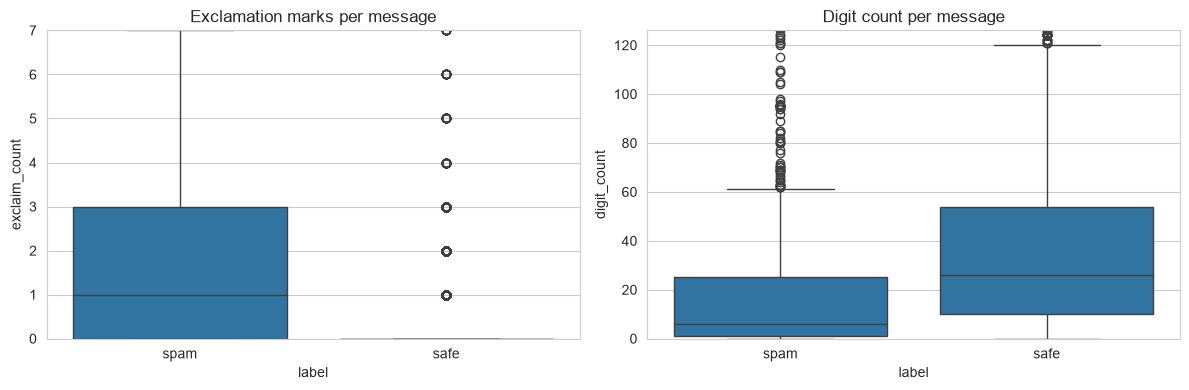

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='label', y='exclaim_count', ax=axes[0])
axes[0].set_ylim(0, df['exclaim_count'].quantile(0.98))
axes[0].set_title('Exclamation marks per message')

sns.boxplot(data=df, x='label', y='digit_count', ax=axes[1])
axes[1].set_ylim(0, df['digit_count'].quantile(0.95))
axes[1].set_title('Digit count per message')

plt.tight_layout()
plt.show()

**Reading this:** spam messages are, on average, *shorter* in word count than safe ones here (safe messages include long forwarded Enron threads), but use noticeably more exclamation marks per message. These simple structural features (length, punctuation, digit density) are cheap signals worth keeping alongside the TF-IDF features in Section 7 — this lines up with Hanif & Ghous (2021)'s point in the proposal's literature review that text preparation matters almost as much as the algorithm.

## 4. Text Cleaning

Standard preprocessing per the proposal's Data Preparation step (Section 4.3): strip the leading `Subject:` marker, lowercase, remove punctuation/digits, collapse whitespace. Stop-word removal is handled later by `TfidfVectorizer(stop_words='english')` rather than a separate step, so the same stop-word list is used consistently at cleaning and vectorizing time.

In [12]:
def clean_text(t):
    t = str(t)
    t = re.sub(r'^subject:\s*', '', t, flags=re.IGNORECASE)
    t = t.lower()
    t = re.sub(r'[^a-z\s]', ' ', t)          # drop punctuation, digits, special chars
    t = re.sub(r'\s+', ' ', t).strip()        # collapse repeated whitespace
    return t

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].sample(3, random_state=42)

,text,clean_text
1436,"Subject: eprm article hi vince , ? as always , it was good to see you aga...",eprm article hi vince as always it was good to see you again in houston we a...
748,Subject: fluid analysis our customer speak volumes about our spur m product...,fluid analysis our customer speak volumes about our spur m product i just wa...
4112,Subject: re : liquids limits oct . 20 john : i will be here most of the we...,re liquids limits oct john i will be here most of the week and am looking fo...


## 5. Empty-after-cleaning Check

Worth checking before modelling: does any message become empty (or near-empty) once cleaned? These would carry no signal for TF-IDF and are candidates to drop.

In [13]:
df['clean_word_count'] = df['clean_text'].str.split().apply(len)
n_empty = (df['clean_word_count'] == 0).sum()
print(f'Messages with zero words after cleaning: {n_empty}')
df['clean_word_count'].describe()

Messages with zero words after cleaning: 0


count    5695.000000
mean      227.021773
std       304.392600
min         1.000000
25%        76.000000
50%       144.000000
75%       274.000000
max      6987.000000
Name: clean_word_count, dtype: float64

## 6. Most Frequent Words by Class

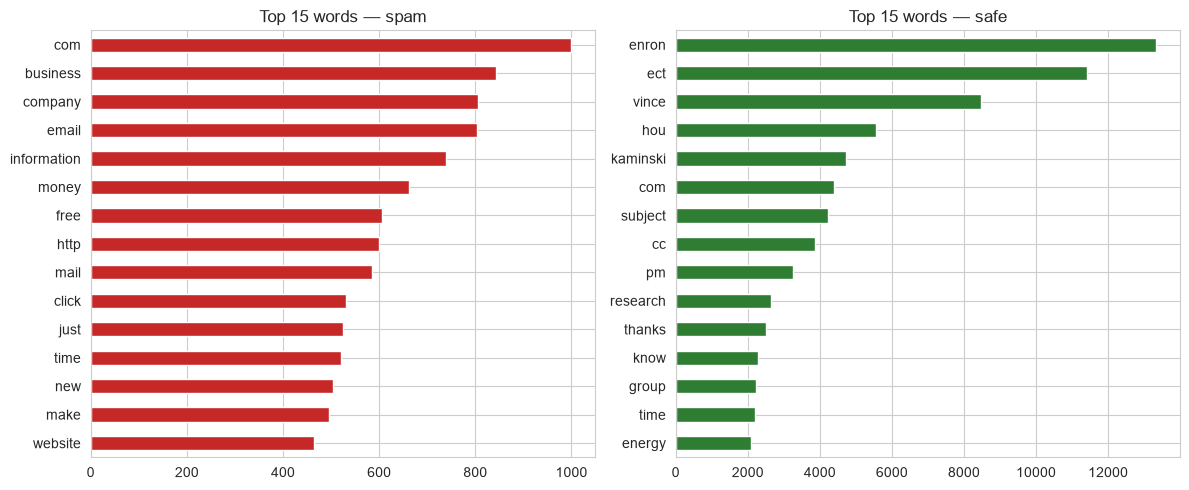

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

def top_words(text_series, n=15):
    cv = CountVectorizer(stop_words='english', max_features=n)
    bow = cv.fit_transform(text_series)
    freqs = np.asarray(bow.sum(axis=0)).ravel()
    return pd.Series(freqs, index=cv.get_feature_names_out()).sort_values(ascending=False)

spam_top = top_words(df.loc[df['spam'] == 1, 'clean_text'])
safe_top = top_words(df.loc[df['spam'] == 0, 'clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
spam_top.sort_values().plot(kind='barh', ax=axes[0], color='#c62828')
axes[0].set_title('Top 15 words — spam')
safe_top.sort_values().plot(kind='barh', ax=axes[1], color='#2e7d32')
axes[1].set_title('Top 15 words — safe')
plt.tight_layout()
plt.show()

**Reading this:** spam is dominated by generic marketing/phishing vocabulary (`free`, `money`, `click`, `business`, `website`), which is exactly what a Naive Bayes model should be able to separate well. Safe mail is dominated by Enron-internal names and workplace terms (`enron`, `ect`, `vince`, `kaminski`, `hou`, `pm`, `thanks`) — a real classifier trained on this data will partly be learning *"this is internal Enron email"* rather than a general notion of *"safe"*, which is worth noting as a limitation if the model is later tested on non-Enron safe mail.

## 7. TF-IDF Preview

A quick look at the feature matrix the modelling notebook will build on (`min_df`/`max_df` limit very rare and very common terms) — not the final feature set, just a check that vectorization behaves sensibly before it's used for training.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.9, max_features=5000)
X = tfidf.fit_transform(df['clean_text'])
print('TF-IDF matrix shape:', X.shape)
print('Vocabulary size:', len(tfidf.vocabulary_))

TF-IDF matrix shape: (5695, 5000)
Vocabulary size: 5000


## 8. Save Cleaned Dataset

In [16]:
cols_to_save = ['text', 'clean_text', 'spam', 'label', 'char_len', 'word_count',
                'exclaim_count', 'digit_count', 'clean_word_count']
df[cols_to_save].to_csv(PROCESSED_PATH, index=False)
print('Saved:', PROCESSED_PATH, df.shape)

Saved: clean_emails.csv (5695, 9)


## 9. Summary — EDA Findings

| Finding | Detail | Action for Data Preparation / Modelling |
|---|---|---|
| Dataset mismatch | Data is Enron email text, not the SMS Spam Collection named in the proposal | Reconcile with the proposal's dataset description before submission |
| Class imbalance | ~76% safe / ~24% spam | Report precision/recall/F1, not just accuracy (proposal Risk #1) |
| Duplicates | 33 exact duplicate messages | Dropped before saving |
| Missing values | None in `text` or `spam` | No imputation needed |
| Length signal | Spam is shorter on average; safe mail includes long forwarded threads | Keep `char_len`/`word_count` as optional extra features |
| Punctuation signal | Spam uses more exclamation marks per message | Keep `exclaim_count` as an optional extra feature |
| Vocabulary | Spam vocabulary is generic marketing/phishing terms; safe vocabulary is Enron-internal names | Model may partly learn "internal Enron email" vs. general "safe"; note as a limitation |
| Cleaning | `clean_text` column ready for vectorization | Feed into `TfidfVectorizer` in the modelling notebook |
